# Modellierung

## Init

In [107]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from xgboost import XGBRegressor
from sklearn.neural_network import MLPRegressor

# Load the dataset
file_path = '../../data/processed/sickness_table.csv'
df = pd.read_csv(file_path)

# Convert date column to datetime
df['date'] = pd.to_datetime(df['date'])

# Datenselektierung

In [130]:
# Prepare features and target
X = df[['calls', 'n_duty', 'n_sby', 'month', 'season', 'day_of_week', 'call_stress', 'n_sick']] #dafted and sby_need werden zusammen mit Zielvariable ausgelassen

#X = df[['n_duty', 'season', 'month', 'day_of_week', 'is_holiday', 'is_weekend']] #auf faktoren beschränkt, die man zu dem Zeitpunkt der Planung wissen kann

y = df['sby_need']

# Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Modellierungvergleiche

In [124]:

# Initialize models
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
    'Support Vector Machine': SVR(),
    'K-Nearest Neighbors': KNeighborsRegressor(),
    'Neural Network': MLPRegressor(random_state=42, max_iter=1000),
    'Lasso Regression': Lasso(random_state=42),
    'Ridge Regression': Ridge(random_state=42),
    'XGBoost': XGBRegressor(random_state=42)
}

# Train and evaluate each model
results = {}
for model_name, model in models.items():
    start_time = time.time()
    model.fit(X_train, y_train)
    end_time = time.time() 

    training_time = end_time - start_time
    y_pred = model.predict(X_test)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    results[model_name] = {'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'R2': r2, "Training Time" : training_time}
    print(f'{model_name} - MAE: {mae}, MSE: {mse}, RMSE: {rmse}, R2: {r2}, "Training Time (s)" : {training_time}')


Linear Regression - MAE: 44.1167737234607, MSE: 3816.597200099855, RMSE: 61.77861442360014, R2: -0.007935347022640649, "Training Time (s)" : 0.002819061279296875
Decision Tree - MAE: 47.729851233422664, MSE: 6505.516332073434, RMSE: 80.6567810668975, R2: -0.71805918150292, "Training Time (s)" : 0.0027539730072021484
Random Forest - MAE: 47.24447096010047, MSE: 6110.64656475389, RMSE: 78.17062469210471, R2: -0.613776970128463, "Training Time (s)" : 0.11791181564331055
Gradient Boosting - MAE: 42.81604362143445, MSE: 4255.585635060712, RMSE: 65.23484985083289, R2: -0.12386897515600004, "Training Time (s)" : 0.05052804946899414
Support Vector Machine - MAE: 24.610817405303457, MSE: 4384.764986833225, RMSE: 66.21755799509089, R2: -0.15798429514669254, "Training Time (s)" : 0.015047550201416016
K-Nearest Neighbors - MAE: 42.66753246753246, MSE: 5087.747705627707, RMSE: 71.32844948285155, R2: -0.34363687871000304, "Training Time (s)" : 0.0011053085327148438
Neural Network - MAE: 45.147968166

Models sorted by MAE:


,MAE,MSE,RMSE,R2,Training Time
Support Vector Machine,24.610817,4384.764987,66.217558,-0.157984,0.015048
K-Nearest Neighbors,42.667532,5087.747706,71.328449,-0.343637,0.001105
Gradient Boosting,42.816044,4255.585635,65.234850,-0.123869,0.050528
Lasso Regression,43.892369,3797.362992,61.622747,-0.002856,0.002361
Ridge Regression,44.113761,3816.355749,61.776660,-0.007872,0.002681
Linear Regression,44.116774,3816.597200,61.778614,-0.007935,0.002819
Neural Network,45.147968,3842.115893,61.984804,-0.014675,0.171620
Random Forest,47.244471,6110.646565,78.170625,-0.613777,0.117912
Decision Tree,47.729851,6505.516332,80.656781,-0.718059,0.002754
XGBoost,47.746415,6476.877429,80.479050,-0.710496,0.040659


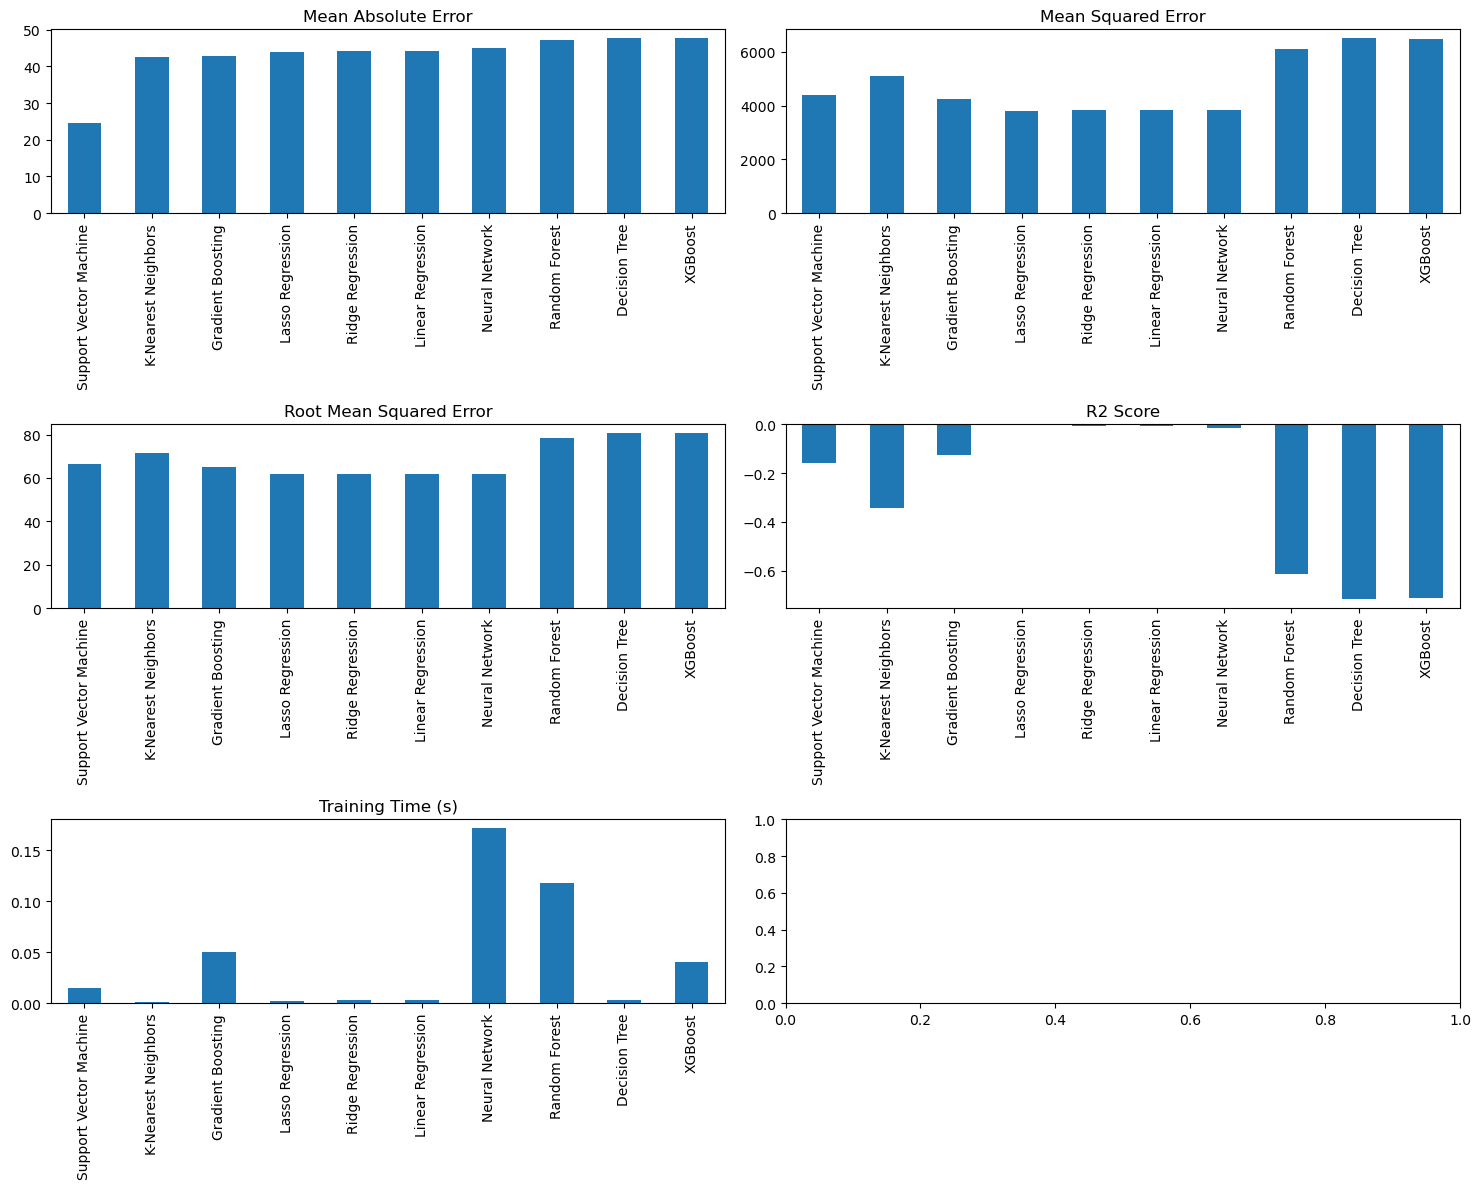

In [125]:
# Convert results to a DataFrame for easier comparison
results_df = pd.DataFrame(results).T

# Sort the models by MAE (you can change the metric to sort by other scores)
results_df_sorted = results_df.sort_values(by='MAE')

print("Models sorted by MAE:")
display(results_df_sorted)

# Visualize the results
fig, axes = plt.subplots(3, 2, figsize=(15, 12))
results_df_sorted['MAE'].plot(kind='bar', ax=axes[0, 0], title='Mean Absolute Error')
results_df_sorted['MSE'].plot(kind='bar', ax=axes[0, 1], title='Mean Squared Error')
results_df_sorted['RMSE'].plot(kind='bar', ax=axes[1, 0], title='Root Mean Squared Error')
results_df_sorted['R2'].plot(kind='bar', ax=axes[1, 1], title='R2 Score')
results_df_sorted['Training Time'].plot(kind='bar', ax=axes[2, 0], title='Training Time (s)')
plt.tight_layout()
plt.show()

In [126]:
# Select the best model based on MAE
best_model_name = results_df_sorted.index[0]
best_model_results = results_df_sorted.loc[best_model_name]

print(f'Best Model: {best_model_name}')
print(best_model_results)

Best Model: Support Vector Machine
MAE                24.610817
MSE              4384.764987
RMSE               66.217558
R2                 -0.157984
Training Time       0.015048
Name: Support Vector Machine, dtype: float64


Final Evaluation of the Best Model (Support Vector Machine):
MAE: 44.858564511393055, MSE: 4770.685743490122, RMSE: 69.0701508865452, R2: -0.2599031383963897


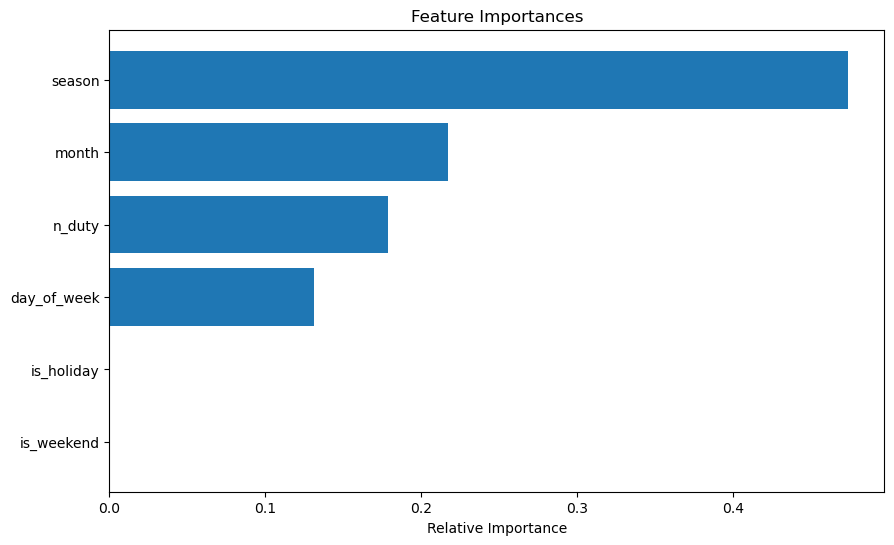

In [127]:
# If further fine-tuning is needed, you can perform hyperparameter tuning on the best model
if best_model_name == 'Random Forest':
    param_grid = {
        'n_estimators': [100, 200],
        'max_depth': [10, 20, None],
        'min_samples_split': [2, 5]
    }
    grid_search = GridSearchCV(RandomForestRegressor(random_state=42), param_grid, cv=5, scoring='neg_mean_absolute_error')
    grid_search.fit(X_train, y_train)
    best_model = grid_search.best_estimator_
elif best_model_name == 'Gradient Boosting':
    param_grid = {
        'n_estimators': [100, 200],
        'learning_rate': [0.01, 0.1, 0.2],
        'max_depth': [3, 5, 7]
    }
    grid_search = GridSearchCV(GradientBoostingRegressor(random_state=42), param_grid, cv=5, scoring='neg_mean_absolute_error')
    grid_search.fit(X_train, y_train)
    best_model = grid_search.best_estimator_
elif best_model_name == 'XGBoost':
    param_grid = {
        'n_estimators': [100, 200],
        'learning_rate': [0.01, 0.1, 0.2],
        'max_depth': [3, 5, 7]
    }
    grid_search = GridSearchCV(XGBRegressor(random_state=42), param_grid, cv=5, scoring='neg_mean_absolute_error')
    grid_search.fit(X_train, y_train)
    best_model = grid_search.best_estimator_
# Add similar tuning for other models if needed

# Train the best model with the entire dataset
best_model.fit(X_train, y_train)
y_pred_best = best_model.predict(X_test)

# Final evaluation of the best model
final_mae = mean_absolute_error(y_test, y_pred_best)
final_mse = mean_squared_error(y_test, y_pred_best)
final_rmse = np.sqrt(final_mse)
final_r2 = r2_score(y_test, y_pred_best)

print(f'Final Evaluation of the Best Model ({best_model_name}):')
print(f'MAE: {final_mae}, MSE: {final_mse}, RMSE: {final_rmse}, R2: {final_r2}')


# Feature Importance for the best model
importances = best_model.feature_importances_
features = X.columns
indices = np.argsort(importances)

plt.figure(figsize=(10, 6))
plt.title('Feature Importances')
plt.barh(range(len(indices)), importances[indices], align='center')
plt.yticks(range(len(indices)), [features[i] for i in indices])
plt.xlabel('Relative Importance')
plt.show()


# Modell mit weniger Features (nur die wichtigsten)

In [128]:
best_model = grid_search.best_estimator_

best_model.fit(X_train, y_train)

X = df[['unix_ts_date', 'month', 'day_of_week', 'is_weekend']]
y = df['n_sick']

# Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

best_model.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             gamma=None, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=0.2, max_bin=None,
             max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=3, max_leaves=None,
             min_child_weight=None, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=200, n_jobs=None,
             num_parallel_tree=None, random_state=42, ...)

# Prediction Test

In [129]:
predict_data = pd.DataFrame([{
        'unix_ts_date' : 1723704690, 
        'month' : 4,
        'day_of_week' : 4,
        'is_weekend' : False

    }])


best_model.predict(predict_data)

array([83.69689], dtype=float32)

# Export model

In [122]:
import joblib

# Modell speichern
joblib.dump(best_model, '../../app/models/readiness_model.pkl')

['../../app/models/readiness_model.pkl']